# 02 · Single-Photon and Nonclassical States

**Covers:** Fock states, creation and annihilation operators, coherent states, photon statistics ($g^{(2)}(0)$, Mandel Q), quadratures, squeezed states and the Wigner function.
**Photonics thread:** the question changes from "which polarization?" to "how many photons are in this waveguide mode?". Laser = coherent state, single-photon source = Fock state $|1\rangle$, squeezed light = sub-vacuum noise for sensing.

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

In [2]:
from math import factorial
N = 40                    # keep photon numbers 0..39 (truncation)
a = qt.destroy(N)         # annihilation operator
n = qt.num(N)             # number operator

## 1. Fock states: counting photons

**Plain words:** $|n\rangle$ means exactly $n$ photons in the mode, like counting marbles in a bucket. Measuring the photon number of $|3\rangle$ gives 3 every time, with zero spread.

**Gap:** the list of possible counts is infinite; QuTiP keeps counts up to $N-1$. Choose $N$ so the chance of reaching the cutoff is negligible.

**One sentence:** a Fock state has an exact photon count.

In [3]:
fock3 = qt.basis(N, 3)
check("<n> of |3>", qt.expect(n, fock3), 3.0)
check("Var(n) of |3>", qt.variance(n, fock3), 0.0)

PASS  <n> of |3>: simulation = 3.0000, theory = 3.0000
PASS  Var(n) of |3>: simulation = 0.0000, theory = 0.0000


## 2. Creation and annihilation operators

**Plain words:** elevator buttons. $a^\dagger$ adds a photon, $a$ removes one, and $a^\dagger a$ counts them.

$$a^\dagger|n\rangle = \sqrt{n+1}\,|n+1\rangle,\qquad a|n\rangle = \sqrt{n}\,|n-1\rangle,\qquad \hat n = a^\dagger a$$

You cannot go below the ground floor: $a|0\rangle = 0$.

**Gap:** the $\sqrt{\ }$ factors are physics, not decoration: the more photons already in a mode, the more likely another joins (bosonic enhancement). It is the reason for the Hong–Ou–Mandel effect in notebook 06.

**One sentence:** $a^\dagger$ adds a photon, $a$ removes one, and $a^\dagger a$ counts them.

In [4]:
check("a+|3> = 2|4>", (a.dag() * fock3).full()[4, 0].real, 2.0)
check("a|3> = sqrt(3)|2>", (a * fock3).full()[2, 0].real, np.sqrt(3))
check("a|0> = 0", (a * qt.basis(N, 0)).norm(), 0.0)
check("a+a equals n", float(np.allclose((a.dag() * a).full(), n.full())), 1.0)

PASS  a+|3> = 2|4>: simulation = 2.0000, theory = 2.0000
PASS  a|3> = sqrt(3)|2>: simulation = 1.7321, theory = 1.7321
PASS  a|0> = 0: simulation = 0.0000, theory = 0.0000
PASS  a+a equals n: simulation = 1.0000, theory = 1.0000


## 3. Coherent states: the laser

**Plain words:** raindrops on a roof. Each drop lands independently at a steady average rate, so the count in any second is random but predictable on average. A laser's photon count follows the same **Poisson** statistics:

$$P(n) = e^{-|\alpha|^2}\frac{|\alpha|^{2n}}{n!},\qquad \langle n\rangle = \mathrm{Var}(n) = |\alpha|^2$$

**Gap:** "laser = coherent state" is an idealization (real lasers drift in phase). A coherent state has an uncertain photon number but a well-defined phase, the opposite trade-off from a Fock state.

**One sentence:** a laser has Poisson-random photon counts; a single-photon source has exactly one.

In [5]:
alpha = 2
coh = qt.coherent(N, alpha)
check("<n> of coherent, alpha=2", qt.expect(n, coh), alpha**2)
check("Var(n) of coherent, alpha=2", qt.variance(n, coh), alpha**2)
for k in range(6):
    sim = abs(qt.basis(N, k).dag() * coh) ** 2
    check(f"Poisson P({k})", sim, np.exp(-alpha**2) * alpha**(2 * k) / factorial(k))

PASS  <n> of coherent, alpha=2: simulation = 4.0000, theory = 4.0000
PASS  Var(n) of coherent, alpha=2: simulation = 4.0000, theory = 4.0000
PASS  Poisson P(0): simulation = 0.0183, theory = 0.0183
PASS  Poisson P(1): simulation = 0.0733, theory = 0.0733
PASS  Poisson P(2): simulation = 0.1465, theory = 0.1465
PASS  Poisson P(3): simulation = 0.1954, theory = 0.1954
PASS  Poisson P(4): simulation = 0.1954, theory = 0.1954
PASS  Poisson P(5): simulation = 0.1563, theory = 0.1563


## 4. The fingerprint: $g^{(2)}(0)$ and Mandel Q

- $g^{(2)}(0) = \langle a^{\dagger 2} a^2\rangle / \langle n\rangle^2$: how often two photons arrive together, compared with random. Single photon: 0. Laser: 1.
- Mandel $Q = (\mathrm{Var}(n) - \langle n\rangle)/\langle n\rangle$. Single photon: −1. Laser: 0.

**Why it matters in practice:** attenuate a laser to one photon per pulse on average and 26 % of pulses still contain two or more photons. That is why true single-photon sources are needed.

**One sentence:** $g^{(2)}(0) = 0$ is the signature of a single photon, $g^{(2)}(0) = 1$ of a laser.

In [6]:
def g2(s):
    return qt.expect(a.dag() * a.dag() * a * a, s) / qt.expect(n, s) ** 2

def mandel_q(s):
    return (qt.variance(n, s) - qt.expect(n, s)) / qt.expect(n, s)

one = qt.basis(N, 1)
check("g2(0) of |1>", g2(one), 0.0)
check("Mandel Q of |1>", mandel_q(one), -1.0)
check("g2(0) of a laser", g2(coh), 1.0)
check("Mandel Q of a laser", mandel_q(coh), 0.0)

weak = qt.coherent(N, 1)                       # attenuated laser, mean 1 photon
p = [abs(qt.basis(N, k).dag() * weak) ** 2 for k in range(N)]
check("P(2 or more) at mean 1", 1 - p[0] - p[1], 1 - 2 * np.exp(-1))

PASS  g2(0) of |1>: simulation = 0.0000, theory = 0.0000
PASS  Mandel Q of |1>: simulation = -1.0000, theory = -1.0000
PASS  g2(0) of a laser: simulation = 1.0000, theory = 1.0000
PASS  Mandel Q of a laser: simulation = 0.0000, theory = 0.0000
PASS  P(2 or more) at mean 1: simulation = 0.2642, theory = 0.2642


## 5. Quadratures: the I/Q picture of light

**Plain words:** any carrier is $I\cos\omega t + Q\sin\omega t$. Light has the same two quadratures, $x$ and $p$:

$$x = \frac{a + a^\dagger}{\sqrt2},\qquad p = \frac{a - a^\dagger}{i\sqrt2},\qquad \mathrm{Var}(x)\,\mathrm{Var}(p) \ge \tfrac14$$

The vacuum has noise $\mathrm{Var}(x) = \mathrm{Var}(p) = \tfrac12$: a round blob. A coherent state is the same blob shifted away from the origin.

**One sentence:** a laser is the vacuum noise blob moved to a new position.

In [7]:
x = (a + a.dag()) / np.sqrt(2)
p_op = -1j * (a - a.dag()) / np.sqrt(2)
vac = qt.basis(N, 0)
check("Var(x) of vacuum", qt.variance(x, vac), 0.5)
check("Var(x) of coherent", qt.variance(x, coh), 0.5)
check("<x> of coherent = sqrt(2)*alpha", qt.expect(x, coh), np.sqrt(2) * alpha)

PASS  Var(x) of vacuum: simulation = 0.5000, theory = 0.5000
PASS  Var(x) of coherent: simulation = 0.5000, theory = 0.5000
PASS  <x> of coherent = sqrt(2)*alpha: simulation = 2.8284, theory = 2.8284


## 6. Squeezed light

**Plain words:** press a round balloon and it gets thin one way and fat the other, keeping its area. Squeezing does that to the noise blob:

$$\mathrm{Var}(x) = \tfrac12 e^{-2r},\qquad \mathrm{Var}(p) = \tfrac12 e^{+2r},\qquad \text{noise reduction} = 8.686\,r\ \text{dB}$$

Squeezed vacuum contains **only even photon numbers**, because the squeezing operator adds photons two at a time ($a^{\dagger 2}$). Physically, one pump photon splits into two.

**Gap:** "nonclassical" does not mean "quiet photon counts". Squeezed vacuum has very bunched counts ($g^{(2)} = 3 + 1/\langle n\rangle$); its nonclassical feature is quadrature noise below the vacuum. Gravitational-wave detectors use exactly this.

**One sentence:** squeezing makes one quadrature quieter than the vacuum and the other noisier, with the product at the minimum.

In [8]:
r = 0.5
sq = qt.squeeze(N, r) * vac
vx, vp = qt.variance(x, sq), qt.variance(p_op, sq)
check("Var(x) squeezed", vx, np.exp(-2 * r) / 2)
check("Var(p) anti-squeezed", vp, np.exp(2 * r) / 2)
check("product = 1/4", vx * vp, 0.25)
check("squeezing in dB", -10 * np.log10(vx / 0.5), 8.686 * r)
check("<n> = sinh^2 r", qt.expect(n, sq), np.sinh(r) ** 2)
check("P(1) = 0 (pairs only)", abs(qt.basis(N, 1).dag() * sq) ** 2, 0.0)
check("P(0) = 1/cosh r", abs(qt.basis(N, 0).dag() * sq) ** 2, 1 / np.cosh(r))
check("g2 = 3 + 1/<n>", g2(sq), 3 + 1 / qt.expect(n, sq))

PASS  Var(x) squeezed: simulation = 0.1839, theory = 0.1839
PASS  Var(p) anti-squeezed: simulation = 1.3591, theory = 1.3591
PASS  product = 1/4: simulation = 0.2500, theory = 0.2500
PASS  squeezing in dB: simulation = 4.3429, theory = 4.3430
PASS  <n> = sinh^2 r: simulation = 0.2715, theory = 0.2715
PASS  P(1) = 0 (pairs only): simulation = 0.0000, theory = 0.0000
PASS  P(0) = 1/cosh r: simulation = 0.8868, theory = 0.8868
PASS  g2 = 3 + 1/<n>: simulation = 6.6827, theory = 6.6827


## 7. The Wigner function

**Plain words:** the Wigner function $W(x, p)$ is the map of where the state sits in phase space, the precise version of the noise blob. Unlike a probability map, it can go **negative**, and a negative value proves the state has no classical description.

| State | Shape | $\pi W(0,0)$ |
|---|---|---|
| Vacuum | round blob | +1 |
| Coherent | shifted round blob | small |
| Squeezed | ellipse | +1 |
| Fock $\lvert1\rangle$ | ring with negative centre | −1 |

**Gap:** $W$ is never measured directly; it is reconstructed from many measurements (tomography, notebook 05). Normalization conventions differ between textbooks; QuTiP uses vacuum variance ½.

**One sentence:** a negative Wigner function is the clearest proof that light is quantum.

In [9]:
xv = np.linspace(-5, 5, 201)          # index 100 is exactly x = p = 0
def w0(state):
    return qt.wigner(state, xv, xv)[100, 100] * np.pi
check("pi W(0,0) vacuum", w0(vac), 1.0)
check("pi W(0,0) squeezed", w0(sq), 1.0)
check("pi W(0,0) Fock |1>", w0(one), -1.0)

PASS  pi W(0,0) vacuum: simulation = 1.0000, theory = 1.0000


PASS  pi W(0,0) squeezed: simulation = 1.0000, theory = 1.0000
PASS  pi W(0,0) Fock |1>: simulation = -1.0000, theory = -1.0000


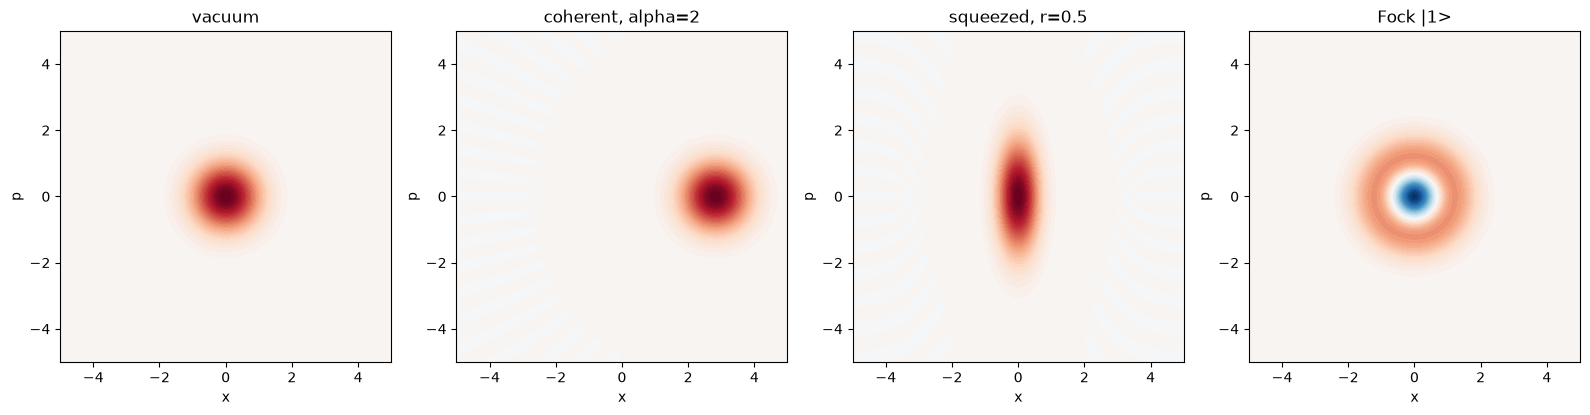

In [10]:
import matplotlib.pyplot as plt
states = [("vacuum", vac), ("coherent, alpha=2", coh), ("squeezed, r=0.5", sq), ("Fock |1>", one)]
levels = np.linspace(-0.32, 0.32, 65)
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, s) in zip(axs, states):
    ax.contourf(xv, xv, qt.wigner(s, xv, xv), levels, cmap="RdBu_r")
    ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("p"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

Red is positive, blue is negative. Only the single photon has a blue centre.

## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [11]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

33 of 33 checks passed
